In [14]:
#Dataset contains risk scores (calculated by Northpointe algorithm) for 7000+ arrests in Broward County, Florida, between 2013 and 2014.
#These risk scores are compared with how many of these individuals were charged for new crimes in the next 2 years (the same analysis used by Northpointe).
import pandas as pd
import matplotlib.pyplot as plt

raw = pd.read_csv("../data/compas-scores-two-years.csv")
print(raw.shape)
raw.head()

Matplotlib is building the font cache; this may take a moment.


(7214, 53)


,id,name,first,last,compas_screening_date,sex,dob,age,age_cat,race,...,v_decile_score,v_score_text,v_screening_date,in_custody,out_custody,priors_count.1,start,end,event,two_year_recid
0,1,miguel hernandez,miguel,hernandez,2013-08-14,Male,1947-04-18,69,Greater than 45,Other,...,1,Low,2013-08-14,2014-07-07,2014-07-14,0,0,327,0,0
1,3,kevon dixon,kevon,dixon,2013-01-27,Male,1982-01-22,34,25 - 45,African-American,...,1,Low,2013-01-27,2013-01-26,2013-02-05,0,9,159,1,1
2,4,ed philo,ed,philo,2013-04-14,Male,1991-05-14,24,Less than 25,African-American,...,3,Low,2013-04-14,2013-06-16,2013-06-16,4,0,63,0,1
3,5,marcu brown,marcu,brown,2013-01-13,Male,1993-01-21,23,Less than 25,African-American,...,6,Medium,2013-01-13,NaN,NaN,1,0,1174,0,0
4,6,bouthy pierrelouis,bouthy,pierrelouis,2013-03-26,Male,1973-01-22,43,25 - 45,Other,...,1,Low,2013-03-26,NaN,NaN,2,0,1102,0,0


In [3]:
#Apply ProPublica's filters
df = raw[
    (raw["days_b_screening_arrest"] <= 30) &
    (raw["days_b_screening_arrest"] >= -30) &
    (raw["is_recid"] != -1) &
    (raw["c_charge_degree"] != "O") &
    (raw["score_text"] != "N/A")
].copy()

print(df.shape)

(6172, 53)


In [4]:
#Check filtering and save cleaned version
df = df[["age", "c_charge_degree", "race", "age_cat", "score_text", "sex",
         "priors_count", "days_b_screening_arrest", "decile_score",
         "is_recid", "two_year_recid"]]

print(df["race"].value_counts())
df.to_csv("../data/compas_clean.csv", index=False)

race
African-American    3175
Caucasian           2103
Hispanic             509
Other                343
Asian                 31
Native American       11
Name: count, dtype: int64


In [6]:
df.head()

,age,c_charge_degree,race,age_cat,score_text,sex,priors_count,days_b_screening_arrest,decile_score,is_recid,two_year_recid
0,69,F,Other,Greater than 45,Low,Male,0,-1.0,1,0,0
1,34,F,African-American,25 - 45,Low,Male,0,-1.0,3,1,1
2,24,F,African-American,Less than 25,Low,Male,4,-1.0,4,1,1
5,44,M,Other,25 - 45,Low,Male,0,0.0,1,0,0
6,41,F,Caucasian,25 - 45,Medium,Male,14,-1.0,6,1,1


In [7]:
# ProPublica treats Medium and High as "high risk" (decile score 5–10)
df["high_risk"] = (df["score_text"] != "Low").astype(int)

# Focus on the two groups ProPublica compares
sub = df[df["race"].isin(["African-American", "Caucasian"])].copy()
print(sub["race"].value_counts())

race
African-American    3175
Caucasian           2103
Name: count, dtype: int64


In [8]:
sub.groupby("race")["two_year_recid"].mean().round(3)

race
African-American    0.523
Caucasian           0.391
Name: two_year_recid, dtype: float64

In [9]:
#confusion matrix
def error_rates(g):
    tp = ((g.high_risk == 1) & (g.two_year_recid == 1)).sum()
    fp = ((g.high_risk == 1) & (g.two_year_recid == 0)).sum()
    tn = ((g.high_risk == 0) & (g.two_year_recid == 0)).sum()
    fn = ((g.high_risk == 0) & (g.two_year_recid == 1)).sum()
    return pd.Series({
        "n": len(g),
        "FPR (flagged, didn't reoffend)": fp / (fp + tn),
        "FNR (not flagged, did reoffend)": fn / (fn + tp),
        "PPV (flagged & did reoffend)": tp / (tp + fp),
        "Accuracy": (tp + tn) / len(g),
    })

rates = sub.groupby("race")[["high_risk", "two_year_recid"]].apply(error_rates)
rates.round(3)

,n,"FPR (flagged, didn't reoffend)","FNR (not flagged, did reoffend)",PPV (flagged & did reoffend),Accuracy
race,,,,,
African-American,3175.0,0.423,0.285,0.650,0.649
Caucasian,2103.0,0.220,0.496,0.595,0.672


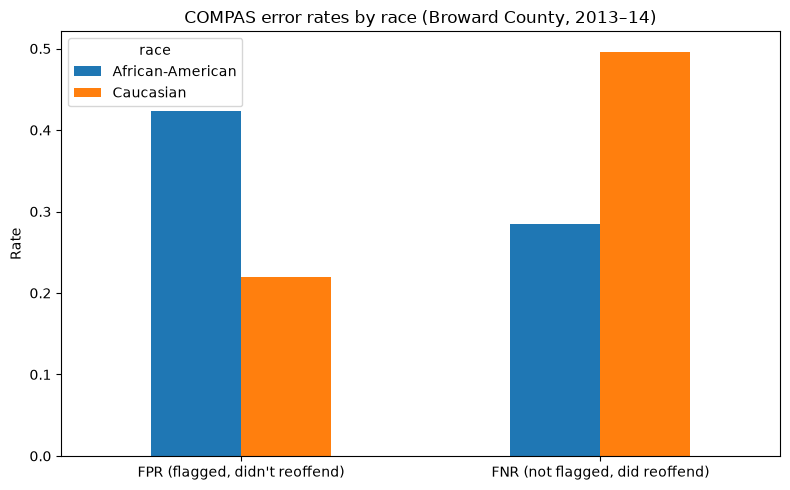

In [15]:
plot_df = rates[["FPR (flagged, didn't reoffend)", "FNR (not flagged, did reoffend)"]].T
ax = plot_df.plot(kind="bar", figsize=(8, 5), rot=0)
ax.set_ylabel("Rate")
ax.set_title("COMPAS error rates by race (Broward County, 2013–14)")
plt.tight_layout()
plt.savefig("../outputs/error_rates_by_race.png", dpi=150)
plt.show()